# Markov switching com trend following

- Primeiramente iremos escolher as ações que iremos utilizar. Utilizaremos as ações que têm melhor relação entre drift e volatilidade, o que é importante para o nosso modelo identificar uma possível tendência.

- Para evitar look-ahead bias, iremos utilizar dados de jan/2001 a dez/2020 para treino e dados de jan/2021 a dez/2025 como teste. No teste, o modelo é reestimado a cada 12 meses (todo 1º de janeiro), usando sempre os 20 anos anteriores.

In [28]:
import numpy as np
import pandas as pd
import yfinance as yf

# Grandes empresas da B3 (tickers atuais no Yahoo).

empresas_brasileiras = [
    "PETR4", "VALE3", "ITUB4", "BBDC4", "BBAS3", "ABEV3", "ITSA4", "B3SA3",
    "GGBR4", "CSNA3", "USIM5", "VIVT3", "CMIG4", "SBSP3", "CPFE3",
    "PCAR3", "TIMS3", "WEGE3", "LREN3", "SUZB3", "RENT3",
]
tickers = [t + ".SA" for t in empresas_brasileiras]


train_start = "2001-01-01" 
train_end   = "2020-12-31"
test_start  = "2021-01-01"   
test_end    = "2025-12-31"
JANELA_ANOS = 20        # anos usados em cada reestimação (janela móvel)

# Só o período de treino (end do yfinance é exclusivo → test_start inclui até 31/12/2020)
dados = yf.download(tickers, start=train_start, end=test_start, auto_adjust=True, progress=False)
# Dias com volume zero são preço repetido pelo Yahoo (sem negociação real) → tratados como faltantes.
# Sem isso, ações com anos de preço "congelado" (ex.: WEGE3 em 2001–2006) têm vol subestimada.
precos = dados["Close"].where(dados["Volume"] > 0)

# Remove ações sem histórico suficiente (exige 90% dos dias com negociação)
cobertura = precos.notna().mean()
removidas = cobertura[cobertura < 0.9].index.tolist()
if removidas:
    print("Removidas por falta de dados:", removidas)
precos = precos.drop(columns=removidas)

# Drift e volatilidade anualizados (retornos log)
retornos = np.log(precos).diff()
drift = retornos.mean() * 252
vol = retornos.std() * np.sqrt(252)

ranking = pd.DataFrame({"drift": drift, "vol": vol, "mu/sigma": drift / vol})
ranking = ranking.sort_values("mu/sigma", ascending=False)

selecionados = ranking.head(3).index.tolist()
display(ranking)
print("Selecionados:", selecionados)

Removidas por falta de dados: ['B3SA3.SA', 'BBDC4.SA', 'CPFE3.SA', 'GGBR4.SA', 'LREN3.SA', 'PCAR3.SA', 'RENT3.SA', 'SUZB3.SA', 'TIMS3.SA', 'WEGE3.SA']


,drift,vol,mu/sigma
Ticker,,,
ABEV3.SA,0.193332,0.290407,0.665727
VALE3.SA,0.170373,0.416145,0.409409
ITUB4.SA,0.139965,0.361589,0.387082
BBAS3.SA,0.165749,0.446419,0.371285
ITSA4.SA,0.148490,0.428956,0.346165
SBSP3.SA,0.119977,0.402558,0.298036
VIVT3.SA,0.092621,0.312239,0.296634
CSNA3.SA,0.141610,0.546319,0.259207
PETR4.SA,0.097020,0.435080,0.222993


Selecionados: ['ABEV3.SA', 'VALE3.SA', 'ITUB4.SA']


# Ações selecionadas
- O trend following, costuma identificar tendencias mais facilmente com um drift maior e uma volatilidade menor. Com isso, escolhemos como ações: ['ABEV3.SA', 'VALE3.SA', 'ITUB4.SA'].
- Dias com volume zero foram tratados como sem negociação: o Yahoo repete o último preço nesses dias, o que gera retornos zero artificiais (a WEGE3, por exemplo, tem preço praticamente congelado entre 2001 e 2006 e por isso foi excluída pelo filtro de cobertura).

In [29]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from bcb import sgs

tickers = selecionados

# end do yfinance é exclusivo → dia seguinte ao fim do teste
fim_download = (pd.Timestamp(test_end) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

prices = {}
for ticker in tickers:
    prices[ticker] = yf.download(ticker, start=train_start, end=fim_download,
                                 interval="1d", auto_adjust=True, progress=False)
    prices[ticker] = prices[ticker].droplevel(1, axis=1)
    # remove dias sem negociação (retorno zero artificial distorce o Markov switching)
    prices[ticker] = prices[ticker][prices[ticker]["Volume"] > 0]

# SGS limita séries diárias a 10 anos por consulta → quebra em blocos
def blocos_sgs(ini, fim, anos=9):
    ini, fim = pd.Timestamp(ini), pd.Timestamp(fim)
    out = []
    while ini <= fim:
        prox = min(ini + pd.DateOffset(years=anos) - pd.Timedelta(days=1), fim)
        out.append((ini.strftime("%Y-%m-%d"), prox.strftime("%Y-%m-%d")))
        ini = prox + pd.Timedelta(days=1)
    return out

blocos = blocos_sgs(train_start, test_end)
cdi_dia = pd.concat([sgs.get({"cdi": 12}, start=ini, end=fim) for ini, fim in blocos])["cdi"] / 100
cdi_dia = cdi_dia[~cdi_dia.index.duplicated()].sort_index()
cdi_anual = (1 + cdi_dia) ** 252 - 1

CDI = 100 * cdi_anual.loc[test_start:test_end].mean()   # média do período de teste (% a.a.), usada no Sharpe
print(f"CDI médio no teste: {CDI:.2f}% a.a.")
print("Blocos SGS:", blocos)

CDI médio no teste: 11.06% a.a.
Blocos SGS: [('2001-01-01', '2009-12-31'), ('2010-01-01', '2018-12-31'), ('2019-01-01', '2025-12-31')]


In [30]:
from scipy.optimize import minimize
from scipy.special import gammaln


class MarkovSwitching:

    nomes = ["p", "q", "mu", "sigma0", "sigma1", "nu"]

    def __init__(self):
        self.params_ = None
        self.res_ = None

    @staticmethod
    def hamilton_filter(y, p, q, mu, sigma0, sigma1, nu=np.inf):
        # Converte em array a serie de retornos 
        y = np.asarray(y, dtype=float)
        # tamanho do array 
        T = len(y)

        # Modelo: y_t = mu + sigma_{s_t} * eps_t   (média única, volatilidade depende do regime)
        # Isola o choque em cada regime: eps = (y - mu) / sigma_s
        eps0 = (y - mu) / sigma0
        eps1 = (y - mu) / sigma1

        # Log-densidade do retorno dado o regime: log f(y | s) = log g(eps) - log sigma_s,
        # onde g é a densidade da t de Student padrão (escrita à mão: muito mais rápida que scipy)
        def log_t(eps, sigma):
            return (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi)
                    - np.log(sigma) - (nu + 1) / 2 * np.log1p(eps ** 2 / nu))
        l0 = log_t(eps0, sigma0)
        l1 = log_t(eps1, sigma1)

        # Escala: divide as duas densidades do dia pela maior delas (soma m de volta no log).
        # Evita que f0 e f1 virem 0 ao mesmo tempo (dens = 0 → log = -inf, xi = 0/0).
        m = np.maximum(l0, l1)
        f0 = np.exp(l0 - m).tolist()   # listas: o loop em Python fica bem mais rápido
        f1 = np.exp(l1 - m).tolist()

        # xi irá ter a probabilidade de cada dia estar no regime 1
        xi = [0.0] * T
        # densidade (escalada) de cada dia, para a log-verossimilhança
        dens_dia = [0.0] * T
        
        # Probabilidade incondicional (estacionária) do regime 1:
        # pi = (1 - q) / (2 - p - q)
        xi_prev = (1 - q) / (2 - p - q)
        
        # Percorre os dias em ordem (cada dia depende do anterior) 
        for t in range(T):
            # Step 1: previsão de P(regime 1) antes de ver y_t
            #  s_t = (1 - q) + lambda * s_{t-1} + v_t,   com lambda = p + q - 1
            
            # Abrindo, com xi_prev = P(s_{t-1} = 1 | y_{t-1}, ...):
            #     (1 - q) + (p + q - 1) * xi_prev
            #   = p * xi_prev + (1 - q) * (1 - xi_prev)
            prior1 = p * xi_prev + (1 - q) * (1 - xi_prev)
            
            # Step 2 (parte B): densidade conjunta de y_t e regime 1
            num1 = f1[t] * prior1
            
            # Step 3: densidade total de y_t, somando os dois regimes
            dens = num1 + f0[t] * (1 - prior1)
            
            # Step 4: Bayes, P(regime 1 | y_t)
            xi[t] = num1 / dens

            # guarda a densidade do dia para a log-verossimilhança
            dens_dia[t] = dens
            
            # o xi de hoje vira o "ontem" do próximo dia
            xi_prev = xi[t]

        # log-verossimilhança = soma de log(dens) + o fator de escala m de cada dia
        loglik = m.sum() + np.log(dens_dia).sum()
        return np.array(xi), loglik

    @staticmethod
    def unpack(theta):
        # limita theta para o exp não estourar quando o otimizador explora valores extremos
        theta = np.clip(theta, -20, 20)
        # clip evita p = q = 1 exatos (0/0 em pi quando o sigmoide satura)
        p = np.clip(1 / (1 + np.exp(-theta[0])), 1e-6, 1 - 1e-6)
        q = np.clip(1 / (1 + np.exp(-theta[1])), 1e-6, 1 - 1e-6)
        mu = theta[2]
        sigma0 = np.exp(theta[3])
        sigma1 = sigma0 * (1 + np.exp(theta[4]))   # garante sigma1 > sigma0 (regime 1 = alta vol)
        nu = 2 + np.exp(theta[5])
        return p, q, mu, sigma0, sigma1, nu

    def neg_loglik(self, theta, y):
        ll = self.hamilton_filter(y, *self.unpack(theta))[1]
        # penaliza parâmetros que geram NaN/inf, para o otimizador fugir dessa região
        return -ll if np.isfinite(ll) else 1e10

    def fit(self, y):
        y = np.asarray(y, dtype=float)
        s = y.std()
        theta0 = np.array([3.0, 3.0, y.mean(), np.log(0.7 * s), 0.0, np.log(3.0)])
        self.res_ = minimize(self.neg_loglik, theta0, args=(y,), method="Nelder-Mead",
                             options={"maxiter": 10000, "xatol": 1e-6, "fatol": 1e-6})
        self.params_ = dict(zip(self.nomes, self.unpack(self.res_.x)))
        return self

    def filter(self, y):
        xi, _ = self.hamilton_filter(y, **self.params_)
        return pd.Series(xi, index=y.index)

In [31]:
params_all = {}
regimes = {}

for ticker in tickers:
    close = prices[ticker]["Close"]
    r = 100 * np.log(close).diff().dropna()   # retorno log em %, como no Hamilton

    # Primeira janela (train_start → train_end): usada na tabela e nos gráficos do treino
    modelo = MarkovSwitching().fit(r[train_start:train_end])
    params_all[ticker] = modelo.params_
    xi_treino = modelo.filter(r[train_start:train_end])

    # Teste: a cada 12 meses (jan → dez), reestima com os JANELA_ANOS anos anteriores
    # e filtra só aquele bloco
    xi_teste = []
    ini_bloco = pd.Timestamp(test_start)
    fim_teste = pd.Timestamp(test_end)
    while ini_bloco <= fim_teste:
        fim_bloco = min(ini_bloco + pd.DateOffset(years=1) - pd.Timedelta(days=1), fim_teste)
        ini_est = ini_bloco - pd.DateOffset(years=JANELA_ANOS)
        fim_est = ini_bloco - pd.Timedelta(days=1)

        modelo_bloco = MarkovSwitching().fit(r[ini_est:fim_est])
        # filtra desde o início da janela (para ter o estado inicial certo) e guarda só o bloco
        xi_bloco = modelo_bloco.filter(r[ini_est:fim_bloco]).loc[ini_bloco:fim_bloco]
        xi_teste.append(xi_bloco)

        ini_bloco = fim_bloco + pd.Timedelta(days=1)

    xi = pd.concat([xi_treino] + xi_teste)
    assert xi.index.is_unique, f"{ticker}: datas duplicadas entre treino e teste"
    regimes[ticker] = pd.DataFrame({"ret": r, "xi": xi}).loc[train_start:]

# Tabela de parâmetros (primeira janela) + métricas da Seção 2
tab = pd.DataFrame(params_all).T
tab["pi"] = (1 - tab["q"]) / (2 - tab["p"] - tab["q"])
tab["dur_alta"] = 1 / (1 - tab["p"])      # dias
tab["dur_baixa"] = 1 / (1 - tab["q"])
tab["lambda"] = tab["p"] + tab["q"] - 1
tab.round(4)

,p,q,mu,sigma0,sigma1,nu,pi,dur_alta,dur_baixa,lambda
ABEV3.SA,0.9680,0.9886,0.0673,1.0905,2.1819,5.4166,0.2632,31.2608,87.4931,0.9566
VALE3.SA,0.9922,0.9978,0.0835,1.6926,3.4254,7.2066,0.2187,128.4281,458.6940,0.9900
ITUB4.SA,0.9792,0.9948,0.0563,1.5954,3.2308,10.2826,0.2008,47.9771,191.0014,0.9739


In [32]:
import backtrader as bt


LOOKBACK = 252   # janela do sinal de tendência (TSMOM)


# Criando uma conta que rentabiliza CDI diariamente (só sobre o capital próprio):
class CarryBroker(bt.brokers.BackBroker):
    params = dict(carry=CDI/100)

    def __init__(self):
        super().__init__()

    def next(self):
        super().next()   # executa primeiro as ordens do dia, depois rende o caixa que sobrou
        daily_carry = (1 + self.p.carry) ** (1/252) - 1
        base = max(min(self.cash, self.getvalue()), 0)
        self.cash += base * daily_carry


class PandasXi(bt.feeds.PandasData):
    lines = ("xi", "mom", "cdi")
    params = (("xi", -1), ("mom", -1), ("cdi", -1))


def make_data(ticker, inicio=test_start, fim=None):
    df = prices[ticker][["Open", "High", "Low", "Close", "Volume"]].copy()
    r = np.log(df["Close"]).diff()
    df["xi"] = regimes[ticker]["xi"].reindex(df.index).ffill()
    df["mom"] = np.sign(r.rolling(LOOKBACK).sum())
    df["cdi"] = cdi_anual.reindex(df.index).ffill()
    df = df.loc[inicio:fim].dropna()
    return PandasXi(dataname=df, name=ticker)


class RegimeTSMOM(bt.Strategy):

    params = dict(thresh=0.5, alloc=0.99)

    def __init__(self):
        self.alvo = {d: None for d in self.datas}

    def next(self):
        self.broker.p.carry = self.datas[0].cdi[0]   # atualiza o CDI do dia no broker

        peso = self.p.alloc / len(self.datas)
        for d in self.datas:
            alvo = d.mom[0] * peso if d.xi[0] < self.p.thresh else 0.0
            if alvo != self.alvo[d]:
                self.order_target_percent(data=d, target=alvo)
                self.alvo[d] = alvo


class TSMOM(RegimeTSMOM):
    params = dict(thresh=1.01)   # filtro desligado: segue sempre o sinal de tendência


class BuyHold(bt.Strategy):

    params = dict(alloc=0.99)

    def __init__(self):
        self.comprou = False

    def next(self):
        self.broker.p.carry = self.datas[0].cdi[0]   # atualiza o CDI do dia no broker

        if self.comprou:
            return
        for d in self.datas:
            self.order_target_percent(data=d, target=self.p.alloc / len(self.datas))
        self.comprou = True


# Função que faz a simulação com o report
def simulate(strategy, datas, **kwargs):

    cerebro = bt.Cerebro(stdstats=True) # Cria o Engine de simulação
    cerebro.broker = CarryBroker(carry=CDI/100)
    for d in datas:
        cerebro.adddata(d) # Adiciona os dados
    cerebro.addstrategy(strategy, **kwargs)  # Adiciona a estratégia

    CUSTO_EMOLUMENTOS = (0.005 + 0.0275) / 100  # taxa de 0.005% + 0.0275% (emolumentos)

    # Ajustando parâmetros de carteira
    cerebro.broker.setcash(1_000_000)
    cerebro.broker.setcommission(commission=CUSTO_EMOLUMENTOS)
    cerebro.broker.set_coc(True)  # cheat on close - para comprar no mesmo dia

    # Performance & Risk Metrics
    cerebro.addanalyzer(bt.analyzers.Returns, _name='returns')
    cerebro.addanalyzer(bt.analyzers.TimeReturn, timeframe=bt.TimeFrame.NoTimeFrame, _name='timereturn')
    cerebro.addanalyzer(bt.analyzers.TimeReturn, timeframe=bt.TimeFrame.Days, _name='ret_diario')
    cerebro.addanalyzer(bt.analyzers.SharpeRatio, _name='sharpe', timeframe=bt.TimeFrame.Days, riskfreerate=CDI/100, annualize=True)
    cerebro.addanalyzer(bt.analyzers.SQN, _name='sqn')  # System Quality Number
    cerebro.addanalyzer(bt.analyzers.DrawDown, _name='drawdown')
    cerebro.addanalyzer(bt.analyzers.Calmar, _name='calmar')
    cerebro.addanalyzer(bt.analyzers.VWR, _name='vwr', timeframe=bt.TimeFrame.Days)  # Variability-Weighted Return

    # Trade
    cerebro.addanalyzer(bt.analyzers.TradeAnalyzer, _name='trade_analyzer')
    cerebro.addanalyzer(bt.analyzers.Transactions, _name='transactions')
    cerebro.addanalyzer(bt.analyzers.PositionsValue, _name='positions')

    # Drawdown
    cerebro.addanalyzer(bt.analyzers.TimeDrawDown, _name='timedrawdown')
    cerebro.addanalyzer(bt.analyzers.GrossLeverage, _name='leverage')

    # Portfolio Analysis
    cerebro.addanalyzer(bt.analyzers.PyFolio, _name='pyfolio')

    # Run the strategy
    results = cerebro.run()
    strat = results[0]

    # Extract and display all performance metrics
    print("=" * 60)
    print("PERFORMANCE METRICS SUMMARY")
    print("=" * 60)

    # Basic Returns (rtot é log-retorno; convertemos para retorno simples)
    returns_analyzer = strat.analyzers.returns.get_analysis()
    print(f"Total Return: {np.exp(returns_analyzer['rtot']) - 1:.2%}")
    print(f"Average Return: {returns_analyzer['ravg']:.4%}")
    print(f"Compound Annual Growth Rate: {returns_analyzer['rnorm100']:.2f}%")

    # Sharpe Ratio
    sharpe = strat.analyzers.sharpe.get_analysis()
    print(f"Sharpe Ratio: {sharpe.get('sharperatio', 'N/A'):.4f}" if sharpe.get('sharperatio') else "Sharpe Ratio: N/A")

    # System Quality Number
    sqn = strat.analyzers.sqn.get_analysis()
    print(f"System Quality Number (SQN): {sqn.get('sqn', 'N/A'):.4f}" if sqn.get('sqn') else "SQN: N/A")

    # DrawDown Analysis
    dd = strat.analyzers.drawdown.get_analysis()
    print(f"Max Drawdown: {dd.max.drawdown:.2f}%")
    print(f"Max Drawdown Duration: {dd.max.len} periods")
    print(f"Max Drawdown Money: ${dd.max.moneydown:,.2f}")

    # Calmar Ratio (Annual Return / Max Drawdown)
    calmar = strat.analyzers.calmar.get_analysis()
    print(f"Calmar Ratio: {calmar.get('calmar', 'N/A'):.4f}" if calmar.get('calmar') else "Calmar Ratio: N/A")

    # VWR - Variability-Weighted Return
    vwr = strat.analyzers.vwr.get_analysis()
    print(f"VWR: {vwr.get('vwr', 'N/A'):.4f}" if vwr.get('vwr') else "VWR: N/A")

    print("\n" + "=" * 60)
    print("TRADE ANALYSIS")
    print("=" * 60)

    # Trade Analysis
    trade_analysis = strat.analyzers.trade_analyzer.get_analysis()
    total_trades = trade_analysis.get('total', {}).get('total', 0)
    print(f"Total Trades: {total_trades}")

    if total_trades > 0:
        won = trade_analysis.get('won', {})
        lost = trade_analysis.get('lost', {})
        pnl = trade_analysis.get('pnl', {})
        length = trade_analysis.get('len', {})
        fechados = trade_analysis.total.get('closed', 0)

        print(f"Total Open Trades: {trade_analysis.total.get('open', 0)}")
        print(f"Total Closed Trades: {fechados}")

        print(f"\nWinning Trades: {won.get('total', 0)}")
        print(f"Losing Trades: {lost.get('total', 0)}")
        # taxa de acerto sobre trades fechados (abertos ainda não têm resultado)
        win_rate = (won.get('total', 0) / fechados) * 100 if fechados else 0.0
        print(f"Win Rate: {win_rate:.1f}%")

        if won.get('total', 0) > 0:
            print(f"Average Win: ${won.get('pnl', {}).get('average', 0):,.2f}")
            print(f"Max Win: ${won.get('pnl', {}).get('max', 0):,.2f}")

        if lost.get('total', 0) > 0:
            print(f"Average Loss: ${lost.get('pnl', {}).get('average', 0):,.2f}")
            print(f"Max Loss: ${lost.get('pnl', {}).get('max', 0):,.2f}")

        print(f"Average Trade: ${pnl.get('net', {}).get('average', 0):,.2f}")
        print(f"Average Trade Length: {length.get('average', 0):.1f} periods")

        # Lucro bruto, perda bruta e Profit Factor
        gross_profit = won.get('pnl', {}).get('total', 0)
        gross_loss = abs(lost.get('pnl', {}).get('total', 0))
        print(f"\nGross Profit: ${gross_profit:,.2f}")
        print(f"Gross Loss: ${-gross_loss:,.2f}")
        print(f"Net Trading P&L: ${gross_profit - gross_loss:,.2f}")
        if gross_loss > 0:
            profit_factor = gross_profit / gross_loss
            print(f"Profit Factor: {profit_factor:.2f}")

    print("\n" + "=" * 60)
    print("PORTFOLIO VALUE")
    print("=" * 60)
    print(f"Starting Portfolio Value: $1,000,000.00")
    print(f"Final Portfolio Value: ${cerebro.broker.getvalue():,.2f}")
    print(f"Total P&L: ${cerebro.broker.getvalue() - 1_000_000:,.2f}")

    # Pyfolio
    pyfolio_analyzer = strat.analyzers.pyfolio
    returns, positions, transactions, gross_lev = pyfolio_analyzer.get_pf_items()
    print(f"\nReturns Series Length: {len(returns)}")
    print(f"Positions Tracked: {len(positions.columns) if hasattr(positions, 'columns') else 0}")
    print(f"Transactions Recorded: {len(transactions)}")

    return cerebro, strat

In [33]:
estrategias = {
    "buy_hold": BuyHold,
    "tsmom": TSMOM,
    "regime_tsmom": RegimeTSMOM,
}
resultados = {}

for t in tickers:
    for nome, estr in estrategias.items():
        print(f"\n########## {t} – {nome} ##########")
        resultados[(t, nome)] = simulate(estr, [make_data(t)])

for nome, estr in estrategias.items():
    print(f"\n########## Carteira – {nome} ##########")
    resultados[("carteira", nome)] = simulate(estr, [make_data(t) for t in tickers])


########## ABEV3.SA – buy_hold ##########
PERFORMANCE METRICS SUMMARY
Total Return: 17.94%
Average Return: 0.0132%
Compound Annual Growth Rate: 3.39%
Sharpe Ratio: -0.1885
SQN: N/A
Max Drawdown: 34.30%
Max Drawdown Duration: 1141 periods
Max Drawdown Money: $435,472.79
Calmar Ratio: N/A
VWR: 1.7985

TRADE ANALYSIS
Total Trades: 1
Total Open Trades: 1
Total Closed Trades: 0

Winning Trades: 0
Losing Trades: 0
Win Rate: 0.0%
Average Trade: $0.00
Average Trade Length: 0.0 periods

Gross Profit: $0.00
Gross Loss: $0.00
Net Trading P&L: $0.00

PORTFOLIO VALUE
Starting Portfolio Value: $1,000,000.00
Final Portfolio Value: $1,179,423.46
Total P&L: $179,423.46

Returns Series Length: 1246
Positions Tracked: 2
Transactions Recorded: 1

########## ABEV3.SA – tsmom ##########
PERFORMANCE METRICS SUMMARY
Total Return: -13.64%
Average Return: -0.0118%
Compound Annual Growth Rate: -2.92%
Sharpe Ratio: -0.4740
System Quality Number (SQN): -2.3632
Max Drawdown: 49.38%
Max Drawdown Duration: 1141 peri

In [34]:
linhas = []
for (ativo, nome), (cerebro, strat) in resultados.items():
    ret = strat.analyzers.returns.get_analysis()
    dd = strat.analyzers.drawdown.get_analysis()
    sharpe = strat.analyzers.sharpe.get_analysis().get("sharperatio")
    ta = strat.analyzers.trade_analyzer.get_analysis()
    fechados = ta.get("total", {}).get("closed", 0)
    ganhos = ta.get("won", {}).get("total", 0)
    lucro_bruto = ta.get("won", {}).get("pnl", {}).get("total", 0)
    perda_bruta = ta.get("lost", {}).get("pnl", {}).get("total", 0)

    linhas.append({
        "Ativo": ativo,
        "Estratégia": nome,
        "Retorno total (%)": 100 * (np.exp(ret["rtot"]) - 1),
        "CAGR (%)": ret["rnorm100"],
        "Sharpe": sharpe,
        "Max Drawdown (%)": dd.max.drawdown,
        "Trades": fechados,
        "Taxa de acerto (%)": 100 * ganhos / fechados if fechados else np.nan,
        "Lucro bruto (R$)": lucro_bruto,
        "Perda bruta (R$)": perda_bruta,
        "Resultado das operações (R$)": lucro_bruto + perda_bruta,
    })

cdi_teste = cdi_dia.loc[test_start:]
linhas.append({"Ativo": "Referência", "Estratégia": "CDI",
               "Retorno total (%)": 100 * ((1 + cdi_teste).prod() - 1),
               "CAGR (%)": 100 * ((1 + cdi_teste).prod() ** (252 / len(cdi_teste)) - 1)})

tabela = pd.DataFrame(linhas).set_index(["Ativo", "Estratégia"]).round(2)
tabela

Retorno total (%)  CAGR (%)  Sharpe  \
Ativo      Estratégia                                          
ABEV3.SA   buy_hold                  17.94      3.39   -0.19   
           tsmom                    -13.64     -2.92   -0.47   
           regime_tsmom             -28.46     -6.55   -0.75   
VALE3.SA   buy_hold                  36.46      6.49    0.00   
           tsmom                    108.76     16.06    0.30   
           regime_tsmom              87.76     13.60    0.22   
ITUB4.SA   buy_hold                  97.41     14.75    0.26   
           tsmom                     -8.37     -1.75   -0.37   
           regime_tsmom             -10.19     -2.15   -0.39   
carteira   buy_hold                  50.61      8.63   -0.03   
           tsmom                     65.74     10.76    0.05   
           regime_tsmom              31.46      5.69   -0.29   
Referência CDI                       68.17     10.99     NaN   

                         Max Drawdown (%)  Trades  Taxa de acerto (%)  \
Ativo      Estratégia                                                   
ABEV3.SA   buy_hold                 34.30     0.0                 NaN   
           tsmom                    49.38    59.0               27.12   
           regime_tsmom             52.67    82.0               30.49   
VALE3.SA   buy_hold                 41.02     0.0                 NaN   
           tsmom                    41.02    48.0               41.67   
           regime_tsmom             41.04    56.0               44.64   
ITUB4.SA   buy_hold                 35.50     0.0                 NaN   
           tsmom                    58.48    39.0               28.21   
           regime_tsmom             59.41    43.0               25.58   
carteira   buy_hold                 26.82     0.0                 NaN   
           tsmom                    14.90   117.0               33.33   
           regime_tsmom             28.12   156.0               34.62   
Referência CDI                        NaN     NaN                 NaN   

                         Lucro bruto (R$)  Perda bruta (R$)  \
Ativo      Estratégia                                         
ABEV3.SA   buy_hold                  0.00              0.00   
           tsmom                285926.21        -771900.31   
           regime_tsmom         542943.59       -1169475.85   
VALE3.SA   buy_hold                  0.00              0.00   
           tsmom               1527829.25       -1329111.06   
           regime_tsmom        1602690.09       -1526492.61   
ITUB4.SA   buy_hold                  0.00              0.00   
           tsmom                256896.29        -760639.16   
           regime_tsmom         280679.70        -796233.11   
carteira   buy_hold                  0.00              0.00   
           tsmom                768599.69        -897619.60   
           regime_tsmom         734255.29       -1032565.27   
Referência CDI                        NaN               NaN   

                         Resultado das operações (R$)  
Ativo      Estratégia                                  
ABEV3.SA   buy_hold                              0.00  
           tsmom                           -485974.10  
           regime_tsmom                    -626532.26  
VALE3.SA   buy_hold                              0.00  
           tsmom                            198718.19  
           regime_tsmom                      76197.48  
ITUB4.SA   buy_hold                              0.00  
           tsmom                           -503742.88  
           regime_tsmom                    -515553.41  
carteira   buy_hold                              0.00  
           tsmom                           -129019.91  
           regime_tsmom                    -298309.98  
Referência CDI                                    NaN

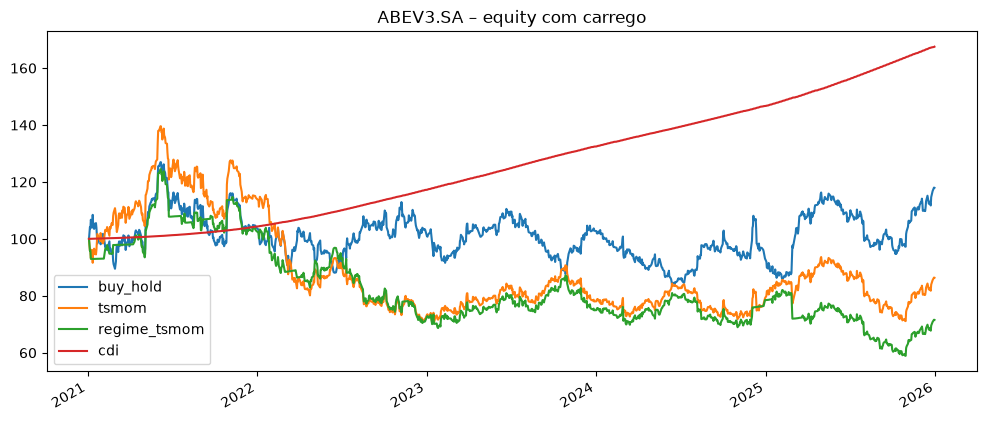

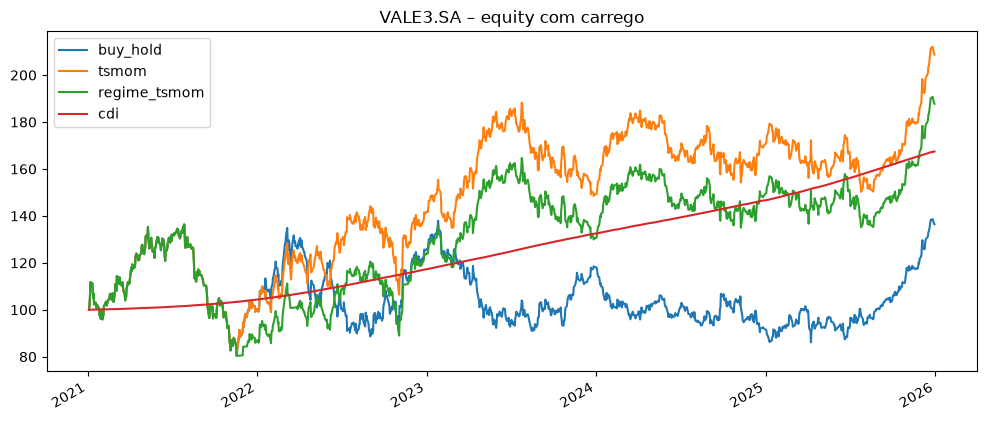

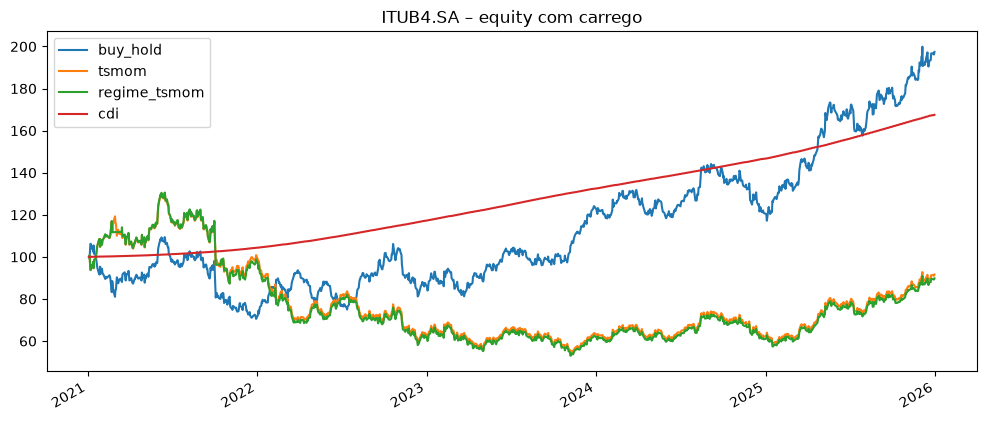

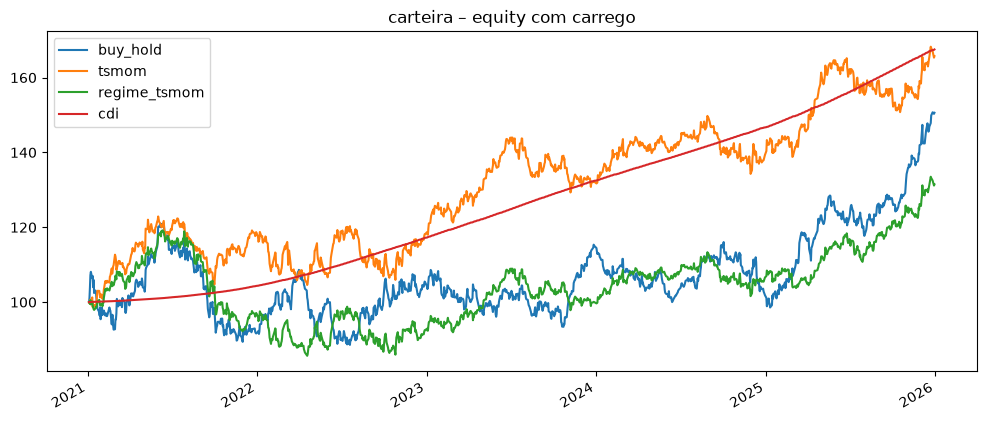

In [35]:
def curva(strat):
    r = pd.Series(strat.analyzers.ret_diario.get_analysis())
    r.index = pd.to_datetime(r.index)
    return 100 * (1 + r).cumprod()


for ativo in tickers + ["carteira"]:
    curvas = pd.DataFrame({nome: curva(resultados[(ativo, nome)][1]) for nome in estrategias})
    curvas["cdi"] = 100 * (1 + cdi_dia.reindex(curvas.index).fillna(0)).cumprod()
    curvas.plot(figsize=(12, 5), title=f"{ativo} – equity com carrego")
    plt.show()

In [36]:
tempo = pd.DataFrame({
    t: {
        "Alta vol – treino (%)": 100 * (regimes[t]["xi"].loc[:train_end] >= 0.5).mean(),
        "Alta vol – teste (%)": 100 * (regimes[t]["xi"].loc[test_start:] >= 0.5).mean(),
        "Trocas de regime – teste": int(((regimes[t]["xi"].loc[test_start:] >= 0.5).astype(int).diff().abs()).sum()),
    }
    for t in tickers
}).T.round(1)
display(tempo)

# % de dias em alta vol por janela de reestimação (jan → dez, ou seja, ano-calendário)
def rotulo_janela(idx):
    return idx.year

alta_por_janela = pd.DataFrame({
    t: 100 * (regimes[t]["xi"].loc[test_start:] >= 0.5)
             .groupby(rotulo_janela(regimes[t].loc[test_start:].index)).mean()
    for t in tickers
}).round(1)
alta_por_janela.index.name = "Janela"
display(alta_por_janela)

,Alta vol – treino (%),Alta vol – teste (%),Trocas de regime – teste
ABEV3.SA,22.1,15.2,56.0
VALE3.SA,22.0,3.1,16.0
ITUB4.SA,18.3,2.0,10.0


,ABEV3.SA,VALE3.SA,ITUB4.SA
Janela,,,
2021,44.1,6.1,10.1
2022,14.8,8.4,0.0
2023,1.6,0.0,0.0
2024,6.8,0.0,0.0
2025,9.2,0.8,0.0
